In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames: 
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/comment-category-prediction-challenge/Sample.csv
/kaggle/input/comment-category-prediction-challenge/train.csv
/kaggle/input/comment-category-prediction-challenge/test.csv


In [2]:
sample = pd.read_csv("/kaggle/input/comment-category-prediction-challenge/Sample.csv").copy(deep=True)
train = pd.read_csv("/kaggle/input/comment-category-prediction-challenge/train.csv").copy(deep=True)
test = pd.read_csv("/kaggle/input/comment-category-prediction-challenge/test.csv").copy(deep=True)

In [3]:
X = train.drop(columns=["label"])
Y = train["label"]
X_test = test

## Milestone 1

In [4]:
train.shape, test.shape

((198000, 15), (102000, 14))

In [5]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 198000 entries, 0 to 197999
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   created_date  198000 non-null  object
 1   post_id       198000 non-null  int64 
 2   emoticon_1    198000 non-null  int64 
 3   emoticon_2    198000 non-null  int64 
 4   emoticon_3    198000 non-null  int64 
 5   upvote        198000 non-null  int64 
 6   downvote      198000 non-null  int64 
 7   if_1          198000 non-null  int64 
 8   if_2          198000 non-null  int64 
 9   race          52577 non-null   object
 10  religion      52577 non-null   object
 11  gender        52577 non-null   object
 12  disability    198000 non-null  bool  
 13  comment       197999 non-null  object
 14  label         198000 non-null  int64 
dtypes: bool(1), int64(9), object(5)
memory usage: 21.3+ MB


In [6]:
train.isnull().sum()

created_date         0
post_id              0
emoticon_1           0
emoticon_2           0
emoticon_3           0
upvote               0
downvote             0
if_1                 0
if_2                 0
race            145423
religion        145423
gender          145423
disability           0
comment              1
label                0
dtype: int64

In [7]:
 train['label'].unique()

array([2, 0, 1, 3])

In [8]:
import matplotlib.pyplot as plt

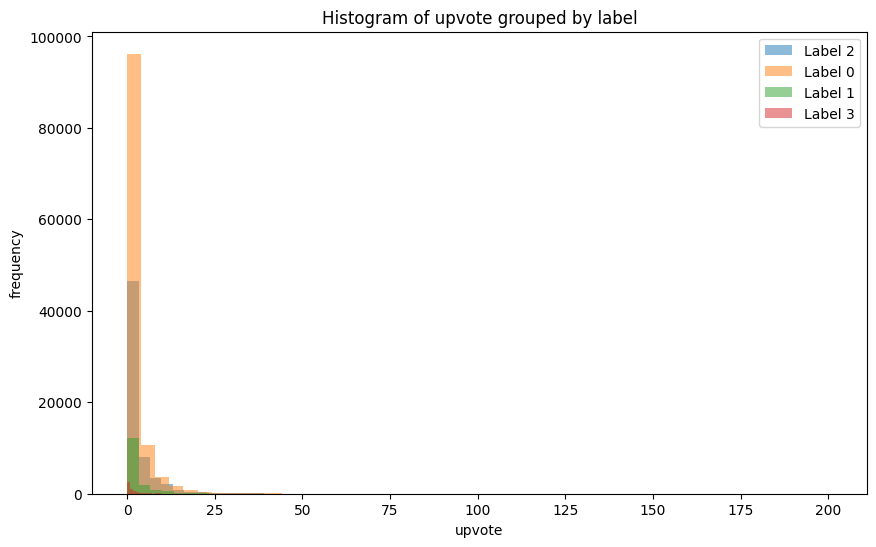

In [9]:
feature="upvote"
labels = train['label'].unique()
plt.figure(figsize=(10,6))
for lbl in labels:
    subset=train[train["label"]==lbl]
    plt.hist(subset[feature],bins=50, alpha=0.5, label=f"Label {lbl}")
plt.xlabel(feature)
plt.ylabel("frequency")
plt.title(f"Histogram of {feature} grouped by label")
plt.legend()
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

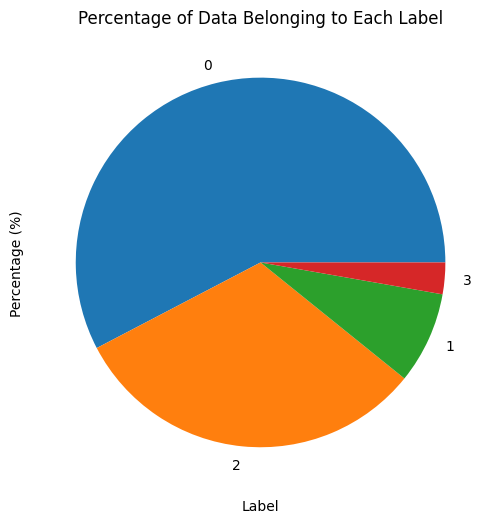

In [10]:
label_counts = train["label"].value_counts(normalize=True) * 100
plt.figure(figsize=(8,6))
label_counts.plot(kind="pie", color="skyblue")
plt.ylabel("Percentage (%)")
plt.xlabel("Label")
plt.title("Percentage of Data Belonging to Each Label")
plt.show

In [11]:
test.describe

<bound method NDFrame.describe of                             created_date  post_id  emoticon_1  emoticon_2  \
0       2024-02-08 13:13:27.998156+00:00       72           2           0   
1       2024-03-01 23:33:25.547123+00:00      123           0           0   
2       2024-02-09 21:52:48.426303+00:00      120           0           0   
3       2024-02-17 03:43:02.980294+00:00      123           0           0   
4       2024-04-24 02:27:57.145155+00:00      123           0           0   
...                                  ...      ...         ...         ...   
101995  2023-09-26 03:14:06.328881+00:00       72           0           0   
101996  2023-08-18 19:30:16.601996+00:00       71           2           0   
101997  2023-10-26 15:41:55.972421+00:00       72           0           0   
101998  2024-02-28 11:25:10.033561+00:00       72           1           0   
101999  2022-12-30 06:10:30.575151+00:00       39           0           0   

        emoticon_3  upvote  downvote  if_

In [12]:
test["if_2"].max()

1798

In [13]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 198000 entries, 0 to 197999
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   created_date  198000 non-null  object
 1   post_id       198000 non-null  int64 
 2   emoticon_1    198000 non-null  int64 
 3   emoticon_2    198000 non-null  int64 
 4   emoticon_3    198000 non-null  int64 
 5   upvote        198000 non-null  int64 
 6   downvote      198000 non-null  int64 
 7   if_1          198000 non-null  int64 
 8   if_2          198000 non-null  int64 
 9   race          52577 non-null   object
 10  religion      52577 non-null   object
 11  gender        52577 non-null   object
 12  disability    198000 non-null  bool  
 13  comment       197999 non-null  object
 14  label         198000 non-null  int64 
dtypes: bool(1), int64(9), object(5)
memory usage: 21.3+ MB


In [18]:
train['created_date'] = pd.to_datetime(train['created_date'])
methods = [m for m in dir(train['created_date'].dt) if "month" in m]
print(methods)

['days_in_month', 'daysinmonth', 'is_month_end', 'is_month_start', 'month', 'month_name']


In [19]:
train['created_date'] =  pd.to_datetime(test['created_date'], errors="coerce")

In [20]:
train['created_date'].dt.month_name().str.lower().value_counts().idxmax()

'may'

In [21]:
x = train["emoticon_1"] + train["emoticon_2"] + train["emoticon_3"]

In [22]:
x.idxmax(), x.max()

(83631, 60)

* **Length** of comment with **lable 3**

In [23]:
x = train[train["label"] == 3]['comment'].apply(lambda y: len(y) if len(y) else 0)
x.median()

128.0

In [24]:
m,M = train['upvote'].min(),train['upvote'].max()

## Milestone 2

In [25]:
x = train[train["label"] == 1]["comment"].apply(lambda y: len(y.split()))

In [26]:
y = train['comment'].apply(lambda x: 1 if "Trump" in str(x) else 0)

In [27]:
y.sum()

np.int64(22402)

In [28]:
x = str(train.loc[0, 'comment']).split()
y = ['a', 'an', 'the', 'and', 'or', 'but', 'if', 'because', 'as', 'of', 'at', 'by', 'for', 'with', 'about', 'to', 'from', 'up', 'on', 'in', 'out', 'over', 'under', 'is', 'are', 'was', 'were', 'be', 'been', 'being', 'have', 'has', 'had', 'do', 'does', 'did', 'it', 'its', 'they', 'them', 'their', 'she', 'her', 'he', 'him', 'his', 'this', 'that', 'which', 'who', 'whom', 'i', 'me', 'my', 'we', 'our', 'you', 'your']
z = len(x)
print(x)
print(z)
for w in x:
    if w in y:
        z -= 1
print(z)        

['She', 'might', 'be', 'a', 'bright', 'spot', 'for', 'a', 'party', 'keou', 'on', 'Oahu', 'dominated', 'by', 'greedy', 'criminals', 'or', 'ethically', 'challenged', 'individuals.']
20
13


In [29]:
x = train['comment'].str.lower()
all_token = set()
for i in x :
    all_token.update(str(i).split())
len(all_token)

425413

* Using TfidfVectorizer for feature extraction 

In [30]:
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer(
    stop_words = "english",
    min_df = 5,
    ngram_range = (1,2)
)

In [31]:
x = vectorizer.fit_transform(train["comment"].fillna("").astype(str))

In [32]:
len(vectorizer.get_feature_names_out())

132974

In [33]:
x.shape

(198000, 132974)

## Milestone 3

In [34]:
from sklearn.model_selection import train_test_split

In [35]:
X_train, X_val, y_train, y_val = train_test_split(X, Y, test_size=0.2, random_state=42)

In [36]:
X_train.shape, X_val.shape, train.shape

((158400, 14), (39600, 14), (198000, 15))

In [37]:
def Uval(s, n):
    p = X_train[str(s)].unique()
    l = p.shape
    print(s,l,n[s] != 0)
    print(p)
    return 

In [38]:
n = X_train.isnull().sum()
for c in X_train.columns:
    Uval(c,n)

created_date (158397,) False
['2024-01-30 10:00:28.895637+00:00' '2024-03-06 19:22:55.838170+00:00'
 '2024-02-28 12:52:37.731199+00:00' ... '2024-02-25 19:47:16.303612+00:00'
 '2024-02-13 19:14:54.813535+00:00' '2023-09-17 08:42:11.281198+00:00']
post_id (52,) False
[ 72  39 123 120  40  91  71  31  73  24 111  85 118 109  61  84  70 105
 115 104 103  75 100  93  83  77 101  89  64  87 102  96  76  42  43  79
 108  90  88  86  74 125 129  50  66  67  95  82 113  65 110  20]
emoticon_1 (35,) False
[ 2  0  5  3  1 12  4  6  7  9 11 18  8 17 27 14 10 13 19 25 22 16 39 15
 47 21 23 36 30 28 20 33 31 24 32]
emoticon_2 (10,) False
[ 0  2  1  3  4  5  6  7 11  8]
emoticon_3 (16,) False
[ 0  1  3  2  6  4  5  7 10 12  9  8 11 13 14 17]
upvote (117,) False
[  1   0   2  14   3  17   5   9  12   4   6  10  35  15   7  22   8  11
  16  24  13  20  18  27  23  19  28  26  25  21  40  32  31  46  36  82
 109  30  78  37  77  45  34  33  86  44  55  29  65  38  57  61  76  41
  42  52  53  48  50  6

In [39]:
X_train['created_date'] = pd.to_datetime(X_train['created_date'], errors="coerce")
X_val['created_date'] = pd.to_datetime(X_val['created_date'], errors="coerce")

In [40]:
[m for m in dir(X_train['created_date'].dt) if "month" in m]

['days_in_month',
 'daysinmonth',
 'is_month_end',
 'is_month_start',
 'month',
 'month_name']

In [41]:
X_train['created_date'].dt.month_name().str.lower().value_counts().idxmax()

'may'

In [42]:
from sklearn.impute import SimpleImputer

* Categorical freature Imputation

In [43]:
cat_imputer = SimpleImputer(strategy='constant', fill_value='none')
X_train[['race','gender','religion']] = cat_imputer.fit_transform(X_train[['race','gender','religion']])
X_val[['race','gender','religion']] = cat_imputer.fit_transform(X_val[['race','gender','religion']])

In [44]:
X_train.isnull().sum()

created_date    0
post_id         0
emoticon_1      0
emoticon_2      0
emoticon_3      0
upvote          0
downvote        0
if_1            0
if_2            0
race            0
religion        0
gender          0
disability      0
comment         0
dtype: int64

* Categoriacl feature Encoding

In [45]:
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

X_train_en = encoder.fit_transform(X_train[['religion','gender','race']])
X_val_en = encoder.fit_transform(X_val[['religion', 'gender', 'race']])


In [46]:
[m for m in dir(X_train_en) if "type" in m]

['astype', 'ctypes', 'dtype']

* Placing it into complete dataframe

In [47]:
X_train_en = pd.DataFrame(X_train_en, columns=encoder.get_feature_names_out(["religion","gender","race"]), index=X_train.index)
X_val_en = pd.DataFrame(X_val_en, columns=encoder.get_feature_names_out(["religion","gender","race"]), index=X_val.index)

In [48]:
X_train = pd.concat([X_train.drop(columns=["religion",'gender','race']), X_train_en], axis=1)
X_val = pd.concat([X_val.drop(columns=["religion",'gender','race']), X_val_en], axis=1)

In [49]:
X_train.shape

(158400, 30)

In [50]:
from sklearn.feature_extraction.text import CountVectorizer
vectorizer = CountVectorizer()

In [51]:
X_train['comment'] = X_train['comment'].fillna("none")
X_val['comment'] = X_val['comment'].fillna("none")

In [469]:
# X_train_vec = vectorizer.fit_transform(X_train['comment'])
# X_val_vec = vectorizer.transform(X_val['comment'])

In [470]:
# row = X_train_vec[1]
# row_sum = row.sum()
# print(row_sum)

In [471]:
# X_val['comment'].head()

In [472]:
# X_train['disability'] = X_train['disability'].astype(int)
# X_val['disability'] = X_val['disability'].astype(int)

In [473]:
# trainSum = X_train['disability'].sum()
# valSum = X_val['disability'].sum()
# totalSum = trainSum + valSum
# print(totalSum)

In [474]:
# from sklearn.preprocessing import StandardScaler

In [475]:
# datetime_cols = X_train.select_dtypes(include=["datetime64[ns]"]).columns
# X_train_no_dt = X_train.drop(columns=datetime_cols)
# X_val_no_dt = X_val.drop(columns=datetime_cols)

* Normalizing Numerical columns

In [476]:
# numeric_cols = X_train_no_dt.select_dtypes(include=["int64","float64"]).columns
# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train_no_dt[numeric_cols])
# X_val_scaled = scaler.transform(X_val_no_dt[numeric_cols])
# num_feature = scaler.n_features_in_

In [477]:
# print(num_feature)

## 1. Multinomial Byesian model 

In [52]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import f1_score

In [53]:
X = train.drop(columns=['label'])
Y = train["label"]
X_train, X_val, y_train, y_val = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)

In [54]:
imputer = SimpleImputer(strategy="most_frequent")
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns)
X_val = pd.DataFrame(imputer.transform(X_val), columns=X_val.columns)

X_train = X_train.map(lambda x: abs(x) if isinstance(x,(int,float)) else x)
X_val = X_val.map(lambda x: abs(x) if isinstance(x,(int,float)) else x)

X_train['created_date'] = pd.to_datetime(X_train['created_date'], errors="coerce")
X_val['created_date'] = pd.to_datetime(X_val['created_date'], errors="coerce")

X_train['day'] = X_train['created_date'].dt.day
X_train['month'] = X_train['created_date'].dt.month
X_train['year'] = X_train['created_date'].dt.year
X_val['day'] = X_val['created_date'].dt.day
X_val['month'] = X_val['created_date'].dt.month
X_val['year'] = X_val['created_date'].dt.year

X_train = X_train.drop(columns=['created_date'])
X_val = X_val.drop(columns=['created_date'])

tfvectorizer = TfidfVectorizer(stop_words='english')

* score in this case
* * train set : 0.486231
* * val set : 0.472618

In [55]:
categorical_cols = X_train.select_dtypes(include=['object']).columns.drop('comment')
encoder = OneHotEncoder(handle_unknown="ignore")

In [56]:
preprocessor = ColumnTransformer(
    transformers=[
        ('tfvectorizer',tfvectorizer, 'comment'),
        ('cat', encoder, categorical_cols),
        ('num', 'passthrough',X_train.select_dtypes(include=['int64','float64']).columns)
    ]
)

In [57]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('nb', MultinomialNB())
])

In [58]:
model.fit(X_train, y_train)
y_train_pred = model.predict(X_train)
train_f1 = f1_score(y_train, y_train_pred, average='macro')
print(train_f1)

0.4862314617544843


In [59]:
y_val_pred = model.predict(X_val)
train_f1 = f1_score(y_val, y_val_pred, average='macro')
print(train_f1)

0.4726189574338925


#### Adding **is_weekend** column and testing same model

In [486]:
# imputer = SimpleImputer(strategy="most_frequent")
# X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns)
# X_val = pd.DataFrame(imputer.transform(X_val), columns=X_val.columns)

# X_train = X_train.map(lambda x: abs(x) if isinstance(x,(int,float)) else x)
# X_val = X_val.map(lambda x: abs(x) if isinstance(x,(int,float)) else x)

# X_train['created_date'] = pd.to_datetime(X_train['created_date'], errors="coerce")
# X_val['created_date'] = pd.to_datetime(X_val['created_date'], errors="coerce")

# X_train['is_weekend'] = (X_train['created_date'].dt.dayofweek >= 5).astype(int)
# X_val['is_weekend'] = (X_val['created_date'].dt.dayofweek >= 5).astype(int)

# X_train = X_train.drop(columns=['created_date'])
# X_val = X_val.drop(columns=['created_date'])

# tfvectorizer = TfidfVectorizer(stop_words='english') 

* score in this case
* * train set : 0.486617
* * val set : 0.472719

## Milestone 4

In [60]:
X = train.drop(columns=['label'])
Y = train['label']
X.shape , Y.shape

((198000, 14), (198000,))

In [61]:
X.isnull().sum(), Y.isnull().sum()

(created_date     96000
 post_id              0
 emoticon_1           0
 emoticon_2           0
 emoticon_3           0
 upvote               0
 downvote             0
 if_1                 0
 if_2                 0
 race            145423
 religion        145423
 gender          145423
 disability           0
 comment              1
 dtype: int64,
 np.int64(0))

In [62]:
X['comment'] = X['comment'].fillna("")

In [63]:
from sklearn.model_selection import train_test_split
X_train, X_val, y_train, y_val = train_test_split(X, Y, test_size=0.4, random_state=2306, stratify=Y)

In [64]:
s_val = y_val.value_counts()
s_train = y_train.value_counts()

In [65]:
train = y_train.value_counts() 
val = y_val.value_counts()

In [66]:
val, s_val

(label
 0    45669
 2    24976
 1     6367
 3     2188
 Name: count, dtype: int64,
 label
 0    45669
 2    24976
 1     6367
 3     2188
 Name: count, dtype: int64)

In [67]:
v = val.apply(lambda x: x/y_val.shape[0])
sv = s_val.apply(lambda x: x/y_val.shape[0])

In [68]:
max(abs(v-sv)), max(v-sv)

(0.0, 0.0)

### Preprocessing 

In [69]:
X_train = X_train.drop(columns=['created_date'])
X_val = X_val.drop(columns=['created_date'])

In [70]:
text_x_train = X_train["comment"]
text_x_test = X_val["comment"]

In [71]:
X_train = X_train.drop(columns=['comment'])
X_test = X_val.drop(columns=['comment'])

In [72]:
from sklearn.compose import ColumnTransformer

In [73]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [74]:
cat_cols = ['race', 'religion', 'gender', 'disability']
nu_cols = ["post_id", "emoticon_1", "emoticon_2", "emoticon_3", "upvote", "downvote", "if_1", "if_2"]

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=True))
])
nu_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler())
])

ct = ColumnTransformer([
    ("categorical", cat_pipeline, cat_cols ),
    ('numerical', nu_pipeline, nu_cols )
], remainder="passthrough", n_jobs=-1, verbose=False)

In [75]:
x_train_tabular = ct.fit_transform(X_train)
x_test_tabular = ct.transform(X_test)

* Normalizing comments

In [76]:
import re
def normalize_text(text):
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'\s+', '  ', text).strip()
    return text

In [77]:
text_x_train_norm = text_x_train.astype(str).apply(normalize_text)
text_x_test_norm = text_x_test.astype(str).apply(normalize_text)

In [78]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [79]:
Tfvectorizer = TfidfVectorizer(stop_words="english", max_features=5000)
tf_idf_train =  Tfvectorizer.fit_transform(text_x_train_norm)
tf_idf_test = Tfvectorizer.transform(text_x_test_norm)


In [80]:
from scipy.sparse import hstack
X_train_final = hstack([x_train_tabular, tf_idf_train])
X_test_final = hstack([x_test_tabular, tf_idf_test])

In [81]:
X_train_final.sum()

np.float64(904262.9332531855)

In [82]:
from sklearn.decomposition import TruncatedSVD

In [83]:
Decomposer = TruncatedSVD(n_components=300, random_state=2306 )

In [84]:
X_train_reduced = Decomposer.fit_transform(X_train_final)
X_test_reduced = Decomposer.transform(X_test_final)

## 2. Random Forest Classifier

In [91]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

In [514]:
# RFC = RandomForestClassifier()
# param_dist = {
#     "n_estimators": [50, 100, 200],
#     "max_depth" : [5, 10, 15]
# }
# randomized_search = RandomizedSearchCV(
#     estimator=RFC,
#     param_distributions=param_dist,
#     n_iter=5,
#     cv=3,
#     random_state=2306,
#     n_jobs=-1
# )
# randomized_search.fit(X_train_reduced, y_train)
# randomized_search.best_params_

In [515]:
# train_pred = randomized_search.best_estimator_.predict(X_train_reduced)
# test_pred = randomized_search.best_estimator_.predict(X_test_reduced)

In [516]:
# print(classification_report(y_val, test_pred))

## 3. Adaptive Boosting Classifier

In [517]:
# from sklearn.ensemble import AdaBoostClassifier

In [518]:
# ABC = AdaBoostClassifier(n_estimators=50, random_state=2306)
# ABC.fit(X_train_reduced,y_train)

In [519]:
# ABC.estimator_errors_

In [520]:
# train_pred = ABC.predict(X_train_reduced)
# test_pred = ABC.predict(X_test_reduced)

In [521]:
# print(classification_report(y_val, test_pred))

In [522]:
# np.var(ABC.estimator_errors_)

### Random Forest Classifier 2

In [523]:
# from sklearn.ensemble import RandomForestClassifier

In [524]:
# RFC2 = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=2306)

In [525]:
# RFC2.fit(X_train_reduced, y_train)
# RFC2.feature_importances_

In [526]:
# np.argmax(RFC2.feature_importances_)

## 4. Multi Layer Perceptron Classifier

In [527]:
# from sklearn.neural_network import MLPClassifier

In [528]:
# MLPC = MLPClassifier(hidden_layer_sizes = (128, 64, 32),
#                         activation = "relu",
#                         random_state = 2306)
# MLPC.fit(X_train_reduced, y_train)

In [529]:
# train_pred = MLPC.predict(X_train_reduced)
# test_pred = MLPC.predict(X_test_reduced)
# print(classification_report(y_val, test_pred))

In [530]:
# print("Done")

In [531]:
# n = X_train_reduced.shape[1]
# layers = [n, 128, 64, 32, 4]
# total_weights = 0
# for i in range(len(layers) - 1):
#     total_weights += layers[i] * layers[i+1]

# print("Number of input features:", n)
# print("Total connection weights:", total_weights)


In [532]:
# MLPC2 = MLPClassifier(hidden_layer_sizes = (128, 64, 32),
#                         activation = "relu",
#                         solver = "adam",
#                         max_iter = 3,
#                         batch_size = 32,
#                         random_state = 2306
#                      )
# MLPC2.fit(X_train_reduced, y_train)

In [533]:
# train_pred = MLPC2.predict(X_train_reduced)
# test_pred = MLPC2.predict(X_test_reduced)
# print(classification_report(y_val, test_pred))

In [534]:
# MLPC2.loss_

In [535]:
# MLPCA = MLPClassifier(hidden_layer_sizes=(100,),alpha=0.0001, max_iter=5, random_state=2306)
# MLPCB = MLPClassifier(hidden_layer_sizes=(100,),alpha=1.0, max_iter=5, random_state=2306)
# MLPCA.fit(X_train_reduced, y_train)
# MLPCB.fit(X_train_reduced, y_train)

In [536]:
# from sklearn.metrics import f1_score

In [537]:
# MFA = f1_score(y_train, MLPCA.predict(X_train_reduced), average="macro" )
# MFB = f1_score(y_train, MLPCB.predict(X_train_reduced), average="macro" )
# abs(MFA - MFB) , MFA, MFB

In [538]:
# from sklearn.metrics import confusion_matrix

In [539]:
# confusion_matrix(y_val, MLPC2.predict(X_test_reduced))

In [540]:
# Training the MLP model as per Q7, generate a confusion matrix for the validation set. What is the sum of the 
# off-diagonal elements (representing the total number of misclassified instances) divided by the total number of samples
# in the validation set? (Round to 4 decimal places).
# conf_mat = confusion_matrix(y_val, MLPC2.predict(X_test_reduced))

In [541]:
# round((conf_mat.sum() - conf_mat.diagonal().sum())/X_test_reduced.shape[1], 4)

## Milestone 5

In [542]:
# X = train.drop(columns=['label'])
# Y = train['label']
# X.shape , Y.shape
# X_test = test

In [543]:
# X['created_date'] = pd.to_datetime(X['created_date'])
# X['year'] = X['created_date'].dt.year
# X['month'] = X['created_date'].dt.month
# X['hour'] = X['created_date'].dt.hour
# X = X.drop(columns=['created_date'])

In [544]:
# X_test['created_date'] = pd.to_datetime(X_test['created_date'])
# X_test['year'] = X_test['created_date'].dt.year
# X_test['month'] = X_test['created_date'].dt.month
# X_test['hour'] = X_test['created_date'].dt.hour
# X_test = X_test.drop(columns=['created_date'])

In [545]:
# X_test[['race','religion','gender']] = X_test[['race','religion', 'gender' ]].fillna("Unknown")
# X[['race','religion','gender']] = X[['race','religion', 'gender' ]].fillna("Unknown")

# X['comment'] = X['comment'].fillna("")
# X_test['comment'] = X_test['comment'].fillna("")

# X['disability'] = X['disability'].astype(int)
# X_test['disability'] = X_test['disability'].astype(int)

In [546]:
# from sklearn.compose import ColumnTransformer
# from sklearn.pipeline import Pipeline
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.preprocessing import OneHotEncoder

In [547]:
# cat_feature = ['race','religion','gender']
# TfidfV = TfidfVectorizer(stop_words="english", max_features=5000)
# OHE = OneHotEncoder(drop='first', handle_unknown='ignore')

In [548]:
# ct = ColumnTransformer(
#     [
#         ('cat_processing', OHE, cat_feature),
#         ('vectorize', TfidfV, 'comment')
#     ],
#     remainder="passthrough"
# )
# X = ct.fit_transform(X)
# X_test = ct.transform(X_test)

In [549]:
# from sklearn.model_selection import train_test_split

In [550]:
# X_train, X_val, y_train, y_val = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)

In [551]:
# X_val.shape, X_train.shape

Train a Multinomial Naive Bayes model using the preprocessed data X_train,y_train. Generate predictions on the validation dataset (X_val,y_val) and evaluate the model using accuracy score. What validation accuracy (using X_val, y_val) does the Naive Bayes model achieve?

(Round the answer to 3 decimal places.)

## * Multinomial Naive Bayes

In [552]:
# from sklearn.naive_bayes import MultinomialNB

In [553]:
# MNB = MultinomialNB()
# MNB.fit(X_train, y_train)

In [554]:
# round(MNB.score(X_val, y_val),3)

In [555]:
# predictions = MNB.predict(X_val)
# print(classification_report(y_val, predictions))

## * Logistic Regression

In [556]:
# from sklearn.linear_model import LogisticRegression

In [557]:
# LgR = LogisticRegression(max_iter=1000, random_state=42)

In [558]:
# LgR.fit(X_train,y_train)
# LgR.score(X_val, y_val)

In [559]:
# LgR.score(X_train, y_train)

In [560]:
# print(classification_report(y_val, LgR.predict(X_val)))

In [561]:
# from sklearn.model_selection import GridSearchCV

#### Using GridSearch for hyperparameter tuning

In [562]:
# LogisticRegression(
#         multi_class='multinomial', 
#         solver='lbfgs', 
#         class_weight=weight, 
#         C=2,                   
#         max_iter=10000          
#     )

In [563]:
# model = LogisticRegression(multi_class='multinomial', class_weight=weight)
# params = {
#     "solver": ["saga", "lbfgs"],
#     "C": [0.1, 1, 2],
#     "max_iter": [1000]
# }
# GSCV = GridSearchCV(estimator=model, param_grid=params, cv=2, scoring='f1_macro', n_jobs=-1 )

In [564]:
# GSCV.fit(X_train, y_train)

Best Prameters for 1000 iteration and defined class weights:
* solver : saga
* C : 2

In [565]:
# GSCV.best_params_

In [566]:
# GSCV.best_estimator_.score(X_val, y_val)

In [567]:
# pred = GSCV.best_estimator_.predict(X_val)
# pred = MNB.predict(X_val)
# f1_score(y_val, pred, average='macro')

In [568]:
# print(classification_report(y_val, pred))

# Exploratory Data Analysis

In [97]:
train = pd.read_csv("/kaggle/input/comment-category-prediction-challenge/train.csv").copy(deep=True)
test = pd.read_csv("/kaggle/input/comment-category-prediction-challenge/test.csv").copy(deep=True)

In [98]:
import matplotlib.pyplot as plt 
import seaborn as sns

In [99]:
X = train.drop(columns=["label"])
Y = train["label"]
X_test = test

In [100]:
X.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 198000 entries, 0 to 197999
Data columns (total 14 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   created_date  198000 non-null  object
 1   post_id       198000 non-null  int64 
 2   emoticon_1    198000 non-null  int64 
 3   emoticon_2    198000 non-null  int64 
 4   emoticon_3    198000 non-null  int64 
 5   upvote        198000 non-null  int64 
 6   downvote      198000 non-null  int64 
 7   if_1          198000 non-null  int64 
 8   if_2          198000 non-null  int64 
 9   race          52577 non-null   object
 10  religion      52577 non-null   object
 11  gender        52577 non-null   object
 12  disability    198000 non-null  bool  
 13  comment       197999 non-null  object
dtypes: bool(1), int64(8), object(5)
memory usage: 19.8+ MB


In [101]:
X['created_date'] = pd.to_datetime(X['created_date'])
X['hour'] = X['created_date'].dt.hour
X['day'] = X['created_date'].dt.day
X['weekend'] = X['created_date'].dt.dayofweek.isin([5, 6]).astype(int)
X['month'] = X['created_date'].dt.month
X['year'] = X['created_date'].dt.year
X = X.drop(columns=['created_date'])

X_test['created_date'] = pd.to_datetime(X_test['created_date'])
X_test['hour'] = X_test['created_date'].dt.hour
X_test['day'] = X_test['created_date'].dt.day
X_test['weekend'] = X_test['created_date'].dt.dayofweek.isin([5, 6]).astype(int)
X_test['month'] = X_test['created_date'].dt.month
X_test['year'] = X_test['created_date'].dt.year
X_test = X_test.drop(columns=['created_date'])

X = X.drop(columns=['post_id'])
X_test = X_test.drop(columns=['post_id'])

In [102]:
X.head()

,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2,race,religion,gender,disability,comment,hour,day,weekend,month,year
0,0,0,0,0,1,0,10,NaN,NaN,NaN,False,She might be a bright spot for a party keou on...,8,18,0,1,2024
1,0,0,0,6,0,0,4,NaN,NaN,NaN,False,"Under Alaska law, a non-tribal member is not b...",21,24,1,3,2024
2,0,1,1,0,0,0,10,NaN,NaN,NaN,False,in the future please spare me your strawman dr...,20,24,0,4,2024
3,0,0,0,5,0,0,10,NaN,NaN,NaN,False,"PS: That should have been ""rot"" instead of ""co...",22,28,1,5,2023
4,0,0,0,0,0,0,10,NaN,NaN,NaN,False,"Today, the confederate flag...tomorrow, the na...",23,9,1,9,2023


In [103]:
[x for x in X.columns if X[x].isnull().sum() > 0]

['race', 'religion', 'gender', 'comment']

In [104]:
X_test[['race','religion','gender']] = X_test[['race','religion', 'gender' ]].fillna("Unknown")
X[['race','religion','gender']] = X[['race','religion', 'gender' ]].fillna("Unknown")

X['comment'] = X['comment'].fillna("")
X_test['comment'] = X_test['comment'].fillna("")

X['disability'] = X['disability'].astype(int)
X_test['disability'] = X_test['disability'].astype(int)

In [105]:
X.describe()

,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2,disability,hour,day,weekend,month,year
count,198000.000000,198000.000000,198000.000000,198000.000000,198000.000000,198000.000000,198000.000000,198000.000000,198000.000000,198000.000000,198000.000000,198000.000000,198000.000000
mean,0.279768,0.048338,0.121071,2.607975,0.666394,1.906152,7.956212,0.013854,12.128833,15.625864,0.313727,5.956101,2023.416975
std,1.023234,0.258477,0.481013,5.054763,2.044335,25.635752,14.839464,0.116883,8.082283,8.845271,0.464008,3.460970,0.564834
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,0.000000,0.000000,1.000000,0.000000,1.000000,2022.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,0.000000,4.000000,8.000000,0.000000,3.000000,2023.000000
50%,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,6.000000,0.000000,13.000000,16.000000,0.000000,5.000000,2023.000000
75%,0.000000,0.000000,0.000000,3.000000,1.000000,4.000000,10.000000,0.000000,20.000000,23.000000,1.000000,9.000000,2024.000000
max,47.000000,11.000000,17.000000,201.000000,107.000000,1860.000000,1833.000000,1.000000,23.000000,31.000000,1.000000,12.000000,2024.000000


In [106]:
pp = pd.concat([X, Y], axis=1)

<function matplotlib.pyplot.show(close=None, block=None)>

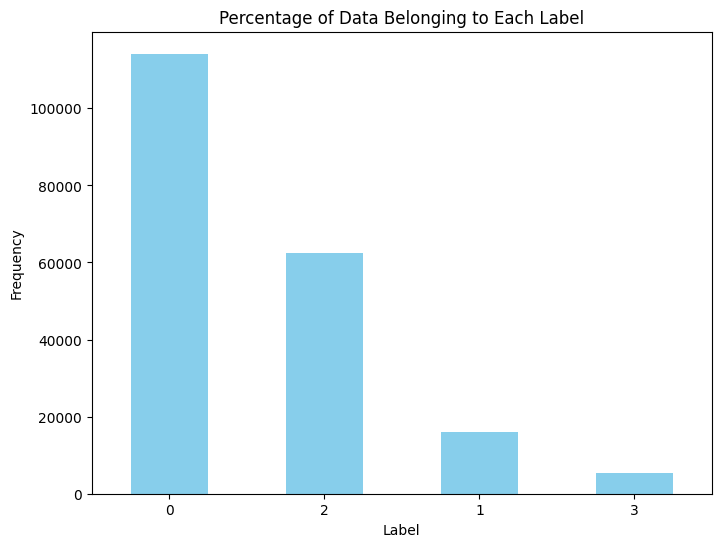

In [107]:
label_counts = train["label"].value_counts()
plt.figure(figsize=(8,6))
label_counts.plot(kind="bar", color="skyblue")
plt.ylabel("Frequency")
plt.xlabel("Label")
plt.xticks(rotation=0)
plt.title("Percentage of Data Belonging to Each Label")
plt.show

In [108]:
# pp = pd.concat([X, Y], axis=1)
# sns.pairplot(pp, hue=Y.name)

<Axes: xlabel='hour', ylabel='count'>

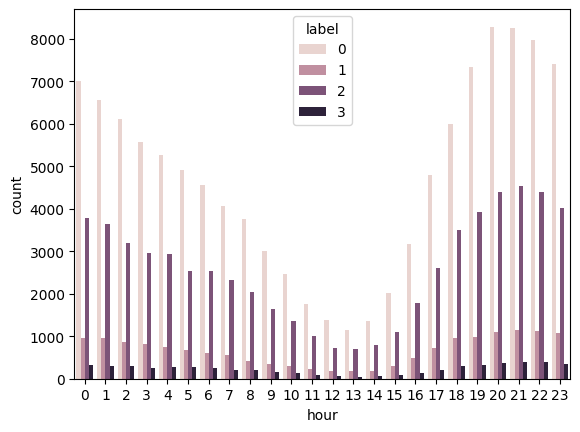

In [109]:
# plot hours
sns.countplot(x="hour",hue="label", data=pp) 

<Axes: xlabel='weekend', ylabel='count'>

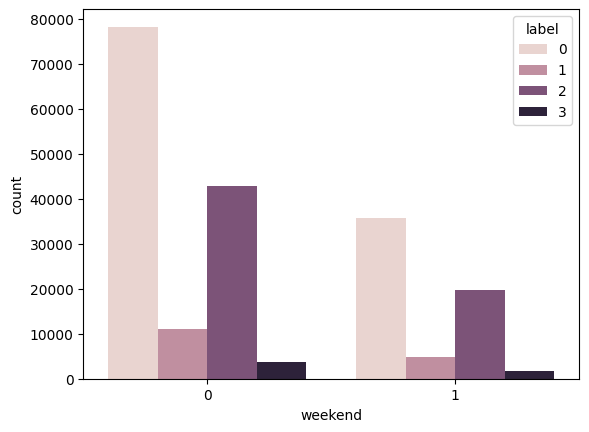

In [110]:
# plot weekend
sns.countplot(x="weekend", hue="label", data=pp)

<Axes: xlabel='day', ylabel='count'>

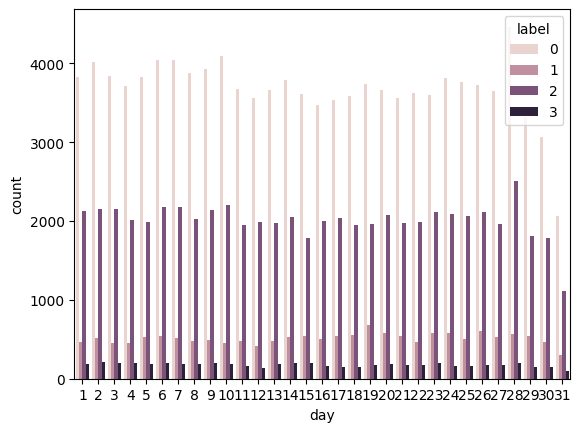

In [111]:
sns.countplot(x="day",hue="label", data=pp)

In [112]:
pp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 198000 entries, 0 to 197999
Data columns (total 18 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   emoticon_1  198000 non-null  int64 
 1   emoticon_2  198000 non-null  int64 
 2   emoticon_3  198000 non-null  int64 
 3   upvote      198000 non-null  int64 
 4   downvote    198000 non-null  int64 
 5   if_1        198000 non-null  int64 
 6   if_2        198000 non-null  int64 
 7   race        198000 non-null  object
 8   religion    198000 non-null  object
 9   gender      198000 non-null  object
 10  disability  198000 non-null  int64 
 11  comment     198000 non-null  object
 12  hour        198000 non-null  int32 
 13  day         198000 non-null  int32 
 14  weekend     198000 non-null  int64 
 15  month       198000 non-null  int32 
 16  year        198000 non-null  int32 
 17  label       198000 non-null  int64 
dtypes: int32(4), int64(10), object(4)
memory usage: 24.2+ MB


<Axes: >

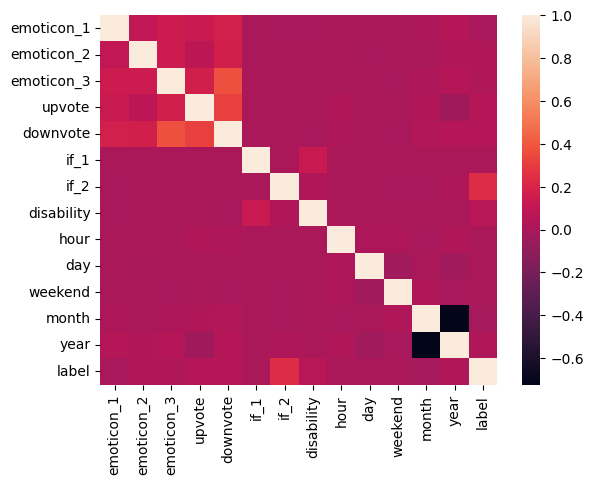

In [113]:
corr = pp[pp.select_dtypes(["int64","float64","int32"]).columns].corr()
sns.heatmap(corr)

* correlation of approx 0.15 between emoticon_1, emoticon_3, upvote, downvote
* * emoticon_1 & emoticon_2 are somewhat related
* emoticon_2, downvote, emoticon_3
* emoticon_3 and downvote have a hight corelation
* upvote and downvote is also hightly corelated
* if_1 and disability
* if_2 and label
* negative correlation of month to year

## Preprocessing 

In [114]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, f1_score, precision_score
from sklearn.model_selection import train_test_split

In [115]:
categorical_features = ['race', 'religion', 'gender']
num_cols = ['emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote', 'downvote', 'if_1', 'if_2']
text_feature = 'comment'

Normalizing comments : Decreases score

In [116]:
# import re
# def normalize_text(text):
#     text = re.sub(r'http\S+|www\S+', '', text)
#     text = re.sub(r'\s+', ' ', text).strip()
#     return text

# Model 1 : Multinomial Naive Bayes

#### Preprocessing


In [117]:
X.columns

Index(['emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote', 'downvote', 'if_1',
       'if_2', 'race', 'religion', 'gender', 'disability', 'comment', 'hour',
       'day', 'weekend', 'month', 'year'],
      dtype='object')

In [118]:
categorical_features = ['race', 'religion', 'gender']
num_cols = ['hour','day','weekend','year', 'emoticon', 'if_2', 'disability']
text_feature = 'comment'

In [119]:
X = train.drop(columns=["label"])
Y = train["label"]
X_test = test

X['created_date'] = pd.to_datetime(X['created_date'])
X['hour'] = X['created_date'].dt.hour
X['day'] = X['created_date'].dt.day
X['weekend'] = X['created_date'].dt.dayofweek.isin([5, 6]).astype(int)
# X['month'] = X['created_date'].dt.month
X['year'] = X['created_date'].dt.year
X['emoticon'] = X['emoticon_3'] + X['emoticon_2'] + X['emoticon_1']
# X['vote'] = X['downvote'] + X['upvote']
X = X.drop(columns=['created_date', 'emoticon_1', 'emoticon_2','emoticon_3', 'upvote','downvote', 'if_1'])

X_test['created_date'] = pd.to_datetime(X_test['created_date'])
X_test['hour'] = X_test['created_date'].dt.hour
X_test['day'] = X_test['created_date'].dt.day
X_test['weekend'] = X_test['created_date'].dt.dayofweek.isin([5, 6]).astype(int)
# X_test['month'] = X_test['created_date'].dt.month
X_test['year'] = X_test['created_date'].dt.year
X_test['emoticon'] = X_test['emoticon_3'] + X_test['emoticon_2'] + X_test['emoticon_1']
# X_test['vote'] = X_test['downvote'] + X_test['upvote']
X_test = X_test.drop(columns=['created_date', 'emoticon_1', 'emoticon_2','emoticon_3', 'upvote','downvote', 'if_1'])

X = X.drop(columns=['post_id'])
X_test = X_test.drop(columns=['post_id'])
X_test[['race','religion','gender']] = X_test[['race','religion', 'gender' ]].fillna("Unknown")
X[['race','religion','gender']] = X[['race','religion', 'gender' ]].fillna("Unknown")

X['comment'] = X['comment'].fillna("")
X_test['comment'] = X_test['comment'].fillna("")

X['disability'] = X['disability'].astype(int)
X_test['disability'] = X_test['disability'].astype(int)

In [120]:
# X['comment'] = X['comment'].apply(normalize_text)
# X_test['comment'] = X_test['comment'].apply(normalize_text)

<Axes: >

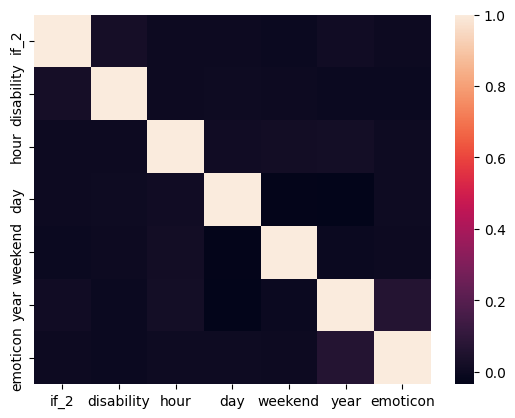

In [121]:
corr = X[X.select_dtypes(["int64","float64","int32"]).columns].corr()
sns.heatmap(corr)

In [122]:
TfidfV = TfidfVectorizer(stop_words="english",sublinear_tf=True, max_features=8000)
OHE = OneHotEncoder(drop='first', handle_unknown='ignore')

In [123]:
ct = ColumnTransformer(
    [
        ('cat_processing', OHE, categorical_features),
        ('vectorize', TfidfV, text_feature)
    ],
    remainder="passthrough"
)
X = ct.fit_transform(X)
X_test = ct.transform(X_test)

In [124]:
X_train, X_val, y_train, y_val = train_test_split(X, Y, test_size=0.2, stratify=Y)

#### oversampling

In [134]:
# from imblearn.over_sampling import ADASYN
# oversampler = ADASYN()
# X_res, y_res = oversampler.fit_resample(X_train, y_train)

#### Model Training

In [126]:
from sklearn.naive_bayes import MultinomialNB

In [128]:
MNB = MultinomialNB(alpha=0.05, class_prior = [0.6, 0.04, 0.25, 0.08])
MNB.fit(X_train, y_train)

MultinomialNB(alpha=0.05, class_prior=[0.6, 0.04, 0.25, 0.08])

In [131]:
# from imblearn.over_sampling import RandomOverSampler
# from sklearn.naive_bayes import MultinomialNB

# ros = RandomOverSampler()
# X_res, y_res = ros.fit_resample(X_train, y_train)

# MNB = MultinomialNB(alpha=0.05, class_prior = [0.6, 0.04, 0.25, 0.08])
# MNB.fit(X_res, y_res)

MultinomialNB(alpha=0.05, class_prior=[0.6, 0.04, 0.25, 0.08])

#### Validation

In [132]:
pred = MNB.predict(X_val)

In [133]:
print(classification_report(y_val, pred))

              precision    recall  f1-score   support

           0       0.95      0.95      0.95     22835
           1       0.69      0.75      0.72      3183
           2       0.84      0.83      0.83     12488
           3       0.50      0.47      0.49      1094

    accuracy                           0.88     39600
   macro avg       0.74      0.75      0.75     39600
weighted avg       0.88      0.88      0.88     39600



# Model2 : LinearSVC

#### Preprocessing

In [135]:
categorical_features = ['race', 'religion', 'gender']
num_cols = ['hour','day','weekend','month','year','emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote', 'downvote', 'if_1', 'if_2', 'disability']
text_feature = 'comment'

In [136]:
X = train.drop(columns=["label"])
Y = train["label"]
X_test = test

X['created_date'] = pd.to_datetime(X['created_date'])
X['hour'] = X['created_date'].dt.hour
X['day'] = X['created_date'].dt.day
X['weekend'] = X['created_date'].dt.dayofweek.isin([5, 6]).astype(int)
X['month'] = X['created_date'].dt.month
X['year'] = X['created_date'].dt.year
X = X.drop(columns=['created_date'])

X_test['created_date'] = pd.to_datetime(X_test['created_date'])
X_test['hour'] = X_test['created_date'].dt.hour
X_test['day'] = X_test['created_date'].dt.day
X_test['weekend'] = X_test['created_date'].dt.dayofweek.isin([5, 6]).astype(int)
X_test['month'] = X_test['created_date'].dt.month
X_test['year'] = X_test['created_date'].dt.year
X_test = X_test.drop(columns=['created_date'])

X = X.drop(columns=['post_id'])
X_test = X_test.drop(columns=['post_id'])
X_test[['race','religion','gender']] = X_test[['race','religion', 'gender' ]].fillna("Unknown")
X[['race','religion','gender']] = X[['race','religion', 'gender' ]].fillna("Unknown")

X['comment'] = X['comment'].fillna("")
X_test['comment'] = X_test['comment'].fillna("")

X['disability'] = X['disability'].astype(int)
X_test['disability'] = X_test['disability'].astype(int)

In [137]:
# ct = ColumnTransformer([
#     ('text', TfidfVectorizer(max_features=8000, sublinear_tf=True), text_feature),
#     ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
#     ('num', StandardScaler(), num_cols)
# ])
# X = ct.fit_transform(X)
# X_test = ct.transform(X_test)

#### Model training

In [138]:
from sklearn.svm import LinearSVC

In [139]:
# X_train, X_val, y_train, y_val = train_test_split(X, Y, test_size=0.2, stratify=Y)

In [140]:
weight={ 0:0.65, 1:0.7, 2:0.7, 3:1.7 }

In [141]:
# LSVC = LinearSVC(class_weight=weight, C=1.0)
# LSVC.fit(X_train,y_train)

In [142]:
# LSVC2 = LinearSVC(class_weight='balanced', C=1)
# LSVC2.fit(X_train,y_train)

#### Validation

In [143]:
# pred = LSVC.predict(X_val)
# print(classification_report(y_val, pred))

In [144]:
# pred2 = LSVC2.predict(X_val)
# print(classification_report(y_val, pred2))

# Model 3 : Logistic Regression

#### Preporcessing

In [145]:
# X.columns

In [146]:
categorical_features = ['race', 'religion', 'gender']
num_cols = ['hour','day','weekend','month','year','emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote', 'downvote', 'if_1', 'if_2', 'disability']
text_feature = 'comment'

In [147]:
X = train.drop(columns=["label"])
Y = train["label"]
X_test = test

X['created_date'] = pd.to_datetime(X['created_date'])
X['hour'] = X['created_date'].dt.hour
X['day'] = X['created_date'].dt.day
X['weekend'] = X['created_date'].dt.dayofweek.isin([5, 6]).astype(int)
X['month'] = X['created_date'].dt.month
X['year'] = X['created_date'].dt.year
X = X.drop(columns=['created_date'])

X_test['created_date'] = pd.to_datetime(X_test['created_date'])
X_test['hour'] = X_test['created_date'].dt.hour
X_test['day'] = X_test['created_date'].dt.day
X_test['weekend'] = X_test['created_date'].dt.dayofweek.isin([5, 6]).astype(int)
X_test['month'] = X_test['created_date'].dt.month
X_test['year'] = X_test['created_date'].dt.year
X_test = X_test.drop(columns=['created_date'])

X = X.drop(columns=['post_id'])
X_test = X_test.drop(columns=['post_id'])
X_test[['race','religion','gender']] = X_test[['race','religion', 'gender' ]].fillna("Unknown")
X[['race','religion','gender']] = X[['race','religion', 'gender' ]].fillna("Unknown")

X['comment'] = X['comment'].fillna("")
X_test['comment'] = X_test['comment'].fillna("")

X['disability'] = X['disability'].astype(int)
X_test['disability'] = X_test['disability'].astype(int)

# X['word_count'] = X['comment'].apply(lambda x: len(x.split(' ')))
# X_test['word_count'] = X_test['comment'].apply(lambda x: len(x.split(' ')))

In [148]:
ct = ColumnTransformer([
    ('text', TfidfVectorizer(max_features=8000, sublinear_tf=True), text_feature), #USING OTHER PARAMETER DECRESES SCORE
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
    ('num', StandardScaler(), num_cols)
])
X = ct.fit_transform(X)
X_test = ct.transform(X_test)

#### Model Training

In [149]:
from sklearn.linear_model import LogisticRegression

In [150]:
X_train, X_val, y_train, y_val = train_test_split(X, Y, test_size=0.2, stratify=Y)

In [193]:
weight={ 0:0.8, 1:1.1, 2:0.7, 3:1.8 }

In [194]:
log_Reg = LogisticRegression(
        multi_class='multinomial', 
        solver='lbfgs', 
        class_weight=weight, 
        C=2,                   
        max_iter=1000         
    )

In [195]:
# log_Reg2 = LogisticRegression(
#         multi_class='multinomial', 
#         solver='saga', 
#         class_weight=weight, 
#         C=2,                   
#         max_iter=1000          
#     )

#### Oversampling

In [196]:
# adaptive synthetic sampling and smote
# from imblearn.over_sampling import ADASYN
# over_sampler = ADASYN()
# X_res, y_res = over_sampler.fit_resample(X_train, y_train)

* testing this found that weight worked better without oversampling.

In [201]:
log_Reg.fit(X, Y)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


LogisticRegression(C=2, class_weight={0: 0.8, 1: 1.1, 2: 0.7, 3: 1.8},
                   max_iter=1000, multi_class='multinomial')

In [198]:
# log_Reg2.fit(X_train, y_train)

#### Validation

In [223]:
pred_train = log_Reg.predict(X_train)
pred_val = log_Reg.predict(X_val)

In [224]:
print(classification_report(y_val, pred_val))

              precision    recall  f1-score   support

           0       0.96      0.95      0.96     22835
           1       0.80      0.83      0.81      3183
           2       0.90      0.90      0.90     12488
           3       0.72      0.80      0.76      1094

    accuracy                           0.92     39600
   macro avg       0.84      0.87      0.86     39600
weighted avg       0.92      0.92      0.92     39600



In [204]:
# pred_train2 = log_Reg2.predict(X_train)
# pred_val2 = log_Reg2.predict(X_val)

In [205]:
# print(classification_report(y_val, pred_val2))

* Manulally optimizing Linear Regression through weight management for lbfgs.

In [206]:
#              precision    recall  f1-score   support

#            0       0.96      0.95      0.95     22835
#            1       0.78      0.71      0.74      3183
#            2       0.80      0.90      0.85     12488    C = 1
#            3       0.86      0.21      0.34      1094  1 1 1 1

#     accuracy                           0.89     39600
#    macro avg       0.85      0.69      0.72     39600
# weighted avg       0.89      0.89      0.89     39600

#     precision    recall  f1-score   support

#            0       0.96      0.94      0.95     22835
#            1       0.66      0.83      0.74      3183
#            2       0.88      0.79      0.83     12488
#            3       0.39      0.80      0.53      1094    balanced

#     accuracy                           0.88     39600
#    macro avg       0.73      0.84      0.76     39600
# weighted avg       0.90      0.88      0.88     39600

#           precision    recall  f1-score   support

#            0       0.96      0.94      0.95     22835
#            1       0.75      0.75      0.75      3183     1 1.5 1 1.5  
#            2       0.82      0.89      0.85     12488
#            3       0.81      0.26      0.40      1094

#     accuracy                           0.89     39600
#    macro avg       0.83      0.71      0.74     39600
# weighted avg       0.89      0.89      0.89     39600

#           precision    recall  f1-score   support

#            0       0.96      0.94      0.95     22835
#            1       0.74      0.77      0.75      3183
#            2       0.83      0.88      0.85     12488
#            3       0.73      0.38      0.50      1094  0.8 1.5 0.9 2

#     accuracy                           0.89     39600   76.61
#    macro avg       0.82      0.74      0.77     39600
# weighted avg       0.89      0.89      0.89     39600

#             precision    recall  f1-score   support

#            0       0.96      0.94      0.95     22835
#            1       0.69      0.82      0.75      3183
#            2       0.85      0.86      0.85     12488
#            3       0.66      0.50      0.57      1094  0.6 2 0.7 2.5

#     accuracy                           0.89     39600   78.
#    macro avg       0.79      0.78      0.78     39600
# weighted avg       0.90      0.89      0.89     39600

#              precision    recall  f1-score   support

#            0       0.96      0.94      0.95     22835
#            1       0.61      0.88      0.72      3183   0.3 2 0.3 3
#            2       0.89      0.77      0.83     12488
#            3       0.45      0.72      0.55      1094

#     accuracy                           0.88     39600
#    macro avg       0.73      0.83      0.76     39600
# weighted avg       0.89      0.88      0.88     39600

#         precision    recall  f1-score   support

#            0       0.96      0.94      0.95     22835
#            1       0.61      0.89      0.72      3183
#            2       0.88      0.78      0.83     12488
#            3       0.48      0.69      0.57      1094   0.3 2 0.3 2.7

#     accuracy                           0.88     39600
#    macro avg       0.73      0.82      0.77     39600
# weighted avg       0.89      0.88      0.88     39600

#              precision    recall  f1-score   support

#            0       0.96      0.94      0.95     22835
#            1       0.70      0.82      0.75      3183
#            2       0.85      0.86      0.85     12488
#            3       0.65      0.52      0.58      1094  0.6 2 0.7 2.4

#     accuracy                           0.90     39600   
#    macro avg       0.79      0.79      0.78     39600
# weighted avg       0.90      0.90      0.90     39600

#        precision    recall  f1-score   support

#            0       0.96      0.94      0.95     22835
#            1       0.73      0.79      0.76      3183
#            2       0.85      0.87      0.86     12488
#            3       0.63      0.56      0.59      1094   0.6, 1.5, 0.7, 2.65

#     accuracy                           0.90     39600
#    macro avg       0.79      0.79      0.79     39600
# weighted avg       0.90      0.90      0.90     39600

#          precision    recall  f1-score   support

#            0       0.96      0.94      0.95     22835
#            1       0.72      0.78      0.75      3183
#            2       0.84      0.86      0.85     12488
#            3       0.64      0.53      0.58      1094  0.65, 1.5, 0.7, 2.65

#     accuracy                           0.89     39600
#    macro avg       0.79      0.78      0.78     39600
# weighted avg       0.90      0.89      0.89     39600

#               precision    recall  f1-score   support

#            0       0.97      0.94      0.95     22835
#            1       0.73      0.82      0.77      3183     C = 2
#            2       0.87      0.88      0.87     12488   best weight
#            3       0.55      0.66      0.60      1094    0.65, 1.5, 0.7, 2.65

#     accuracy                           0.90     39600
#    macro avg       0.78      0.82      0.80     39600
# weighted avg       0.91      0.90      0.90     39600

#             precision    recall  f1-score   support

#            0       0.97      0.94      0.95     22835
#            1       0.73      0.82      0.77      3183     C = 3
#            2       0.87      0.88      0.88     12488   best weight
#            3       0.55      0.70      0.62      1094    0.65, 1.5, 0.7, 2.65

#     accuracy                           0.90     39600
#    macro avg       0.78      0.83      0.80     39600
# weighted avg       0.91      0.90      0.90     39600

# Model 4 : Random Forest Classifier

#### Preprocessing

In [207]:
# X = train.drop(columns=["label"])
# Y = train["label"]
# X_test = test

# X['created_date'] = pd.to_datetime(X['created_date'])
# X['hour'] = X['created_date'].dt.hour
# X['day'] = X['created_date'].dt.day
# X['weekend'] = X['created_date'].dt.dayofweek.isin([5, 6]).astype(int)
# X['month'] = X['created_date'].dt.month
# X['year'] = X['created_date'].dt.year
# X = X.drop(columns=['created_date'])

# X_test['created_date'] = pd.to_datetime(X_test['created_date'])
# X_test['hour'] = X_test['created_date'].dt.hour
# X_test['day'] = X_test['created_date'].dt.day
# X_test['weekend'] = X_test['created_date'].dt.dayofweek.isin([5, 6]).astype(int)
# X_test['month'] = X_test['created_date'].dt.month
# X_test['year'] = X_test['created_date'].dt.year
# X_test = X_test.drop(columns=['created_date'])

# X = X.drop(columns=['post_id'])
# X_test = X_test.drop(columns=['post_id'])
# X_test[['race','religion','gender']] = X_test[['race','religion', 'gender' ]].fillna("Unknown")
# X[['race','religion','gender']] = X[['race','religion', 'gender' ]].fillna("Unknown")

# X['comment'] = X['comment'].fillna("")
# X_test['comment'] = X_test['comment'].fillna("")

# X['disability'] = X['disability'].astype(int)
# X_test['disability'] = X_test['disability'].astype(int)

In [208]:
# ct = ColumnTransformer([
#     ('text', TfidfVectorizer(max_features=8000, sublinear_tf=True), text_feature), #USING OTHER PARAMETER DECRESES SCORE
#     ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
#     ('num', 'passthrough', num_cols)
# ])
# X = ct.fit_transform(X)
# X_test = ct.transform(X_test)

In [209]:
# X_train, X_val, y_train, y_val = train_test_split(X, Y, test_size=0.2, stratify=Y)

In [210]:
# from sklearn.ensemble import RandomForestClassifier
# # from imblearn.over_sampling  import RandomOverSampler

# # ros=RandomOverSampler()
# # X_train, y_train = ros.fit_resample(X_train, y_train)

# RFC = RandomForestClassifier(
#     n_estimators=10,
#     class_weight={0:1, 1:2, 2:1, 3:8}
# )
# RFC.fit(X_train, y_train)

In [211]:
# pred_val = RFC.predict(X_val)

In [212]:
# print(classification_report(y_val, pred_val))

# Model 5 : Gradient Boosting Classifier

In [213]:
#               precision    recall  f1-score   support

#            0       0.97      0.95      0.96     22835
#            1       0.78      0.72      0.75      3183
#            2       0.82      0.90      0.86     12488
#            3       0.65      0.31      0.42      1094

#     accuracy                           0.90     39600
#    macro avg       0.80      0.72      0.75     39600
# weighted avg       0.90      0.90      0.90     39600


In [214]:
# from sklearn.ensemble import GradientBoostingClassifier
# GBC = GradientBoostingClassifier(
#     n_estimators=10,
#     learning_rate=0.05,
#     max_depth=4,
#     subsample=0.8,
#     min_samples_leaf=5
# )
# GBC.fit(X_train, y_train)

In [215]:
# pred_val = GBC.predict(X_val)

In [216]:
# print(classification_report(y_val, pred_val))

# Comparison of Models

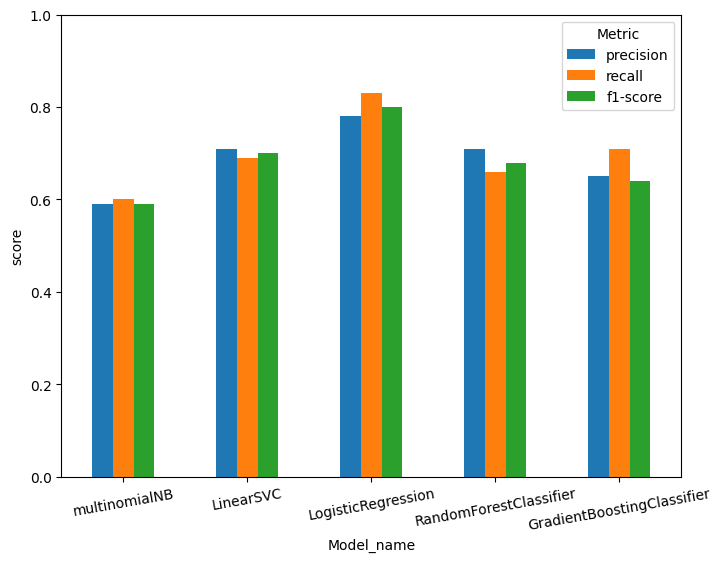

In [217]:
# # model 1 mulitnomialNB
#               precision    recall  f1-score   support

#            0       0.92      0.90      0.91     22835
#            1       0.40      0.36      0.38      3183
#            2       0.74      0.77      0.76     12488
#            3       0.33      0.35      0.34      1094

#     accuracy                           0.80     39600
#    macro avg       0.59      0.60      0.59     39600
# weighted avg       0.80      0.80      0.80     39600

# # model 2 LinearSVC
#               precision    recall  f1-score   support

#            0       0.82      0.89      0.85     22835
#            1       0.68      0.69      0.69      3183
#            2       0.81      0.68      0.74     12488
#            3       0.53      0.49      0.51      1094

#     accuracy                           0.80     39600
#    macro avg       0.71      0.69      0.70     39600
# weighted avg       0.80      0.80      0.79     39600

# # model 3 Logistic Regresssion
#               precision    recall  f1-score   support

#            0       0.97      0.94      0.95     22835
#            1       0.73      0.81      0.77      3183
#            2       0.87      0.88      0.87     12488
#            3       0.56      0.70      0.62      1094

#     accuracy                           0.90     39600
#    macro avg       0.78      0.83      0.80     39600
# weighted avg       0.91      0.90      0.90     39600

# # model 4 Random Forest Classifier
#               precision    recall  f1-score   support

#            0       0.87      0.94      0.90     22835
#            1       0.65      0.71      0.68      3183
#            2       0.81      0.70      0.75     12488
#            3       0.53      0.31      0.39      1094

#     accuracy                           0.83     39600
#    macro avg       0.71      0.66      0.68     39600
# weighted avg       0.82      0.83      0.82     39600

# # model 5 Gradient Boosting Classifier


comp = np.array([
["Model_name","precision","recall","f1-score"],
["multinomialNB", 0.59, 0.60 ,0.59],
["LinearSVC", 0.71, 0.69 ,0.70],
["LogisticRegression", 0.78, 0.83 ,0.80],
["RandomForestClassifier", 0.71, 0.66 ,0.68],
["GradientBoostingClassifier", 0.65, 0.71, 0.64]
])
comp_df = pd.DataFrame(comp[1:], columns=comp[0])
comp_df[["precision","recall","f1-score"]] = comp_df[["precision","recall","f1-score"]].astype(float)
comp_df.set_index("Model_name").plot(kind='bar', figsize=(8,6))
plt.ylabel("score")
plt.ylim(0,1)
plt.xticks(rotation=10)
plt.legend(title="Metric")
plt.show()

# Submission Part

In [218]:
y_pred_test = log_Reg.predict(X_test)


submission = pd.DataFrame({
    "ID": sample["ID"], 
    "label": y_pred_test
})

submission['label'] = submission['label'].astype(int)
submission.to_csv("submission.csv", index=False)
print("Submission file saved!")

Submission file saved!


In [219]:
import os

In [220]:
print(os.getcwd())

/kaggle/working


In [221]:
!ls /kaggle/working/

submission.csv


In [222]:
submission.head()

,ID,label
0,1,2
1,2,2
2,3,0
3,4,0
4,5,2
